# BrandPulse AI: Sentiment Analysis on Twitter Data using Classical NLP

## 1. Importing Libraries and Loading the Dataset

In [33]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from utils import clean

df = pd.read_csv("Tweets.csv")[["tweet_created", "airline", "airline_sentiment", "text"]]
print(df.shape)
df.head()

(14640, 4)


,tweet_created,airline,airline_sentiment,text
0,2015-02-24 11:35:52 -0800,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,2015-02-24 11:15:59 -0800,Virgin America,positive,@VirginAmerica plus you've added commercials t...
2,2015-02-24 11:15:48 -0800,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I n...
3,2015-02-24 11:15:36 -0800,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,2015-02-24 11:14:45 -0800,Virgin America,negative,@VirginAmerica and it's a really big bad thing...


	## 2. Exploratory Data Analysis: Class Distribution

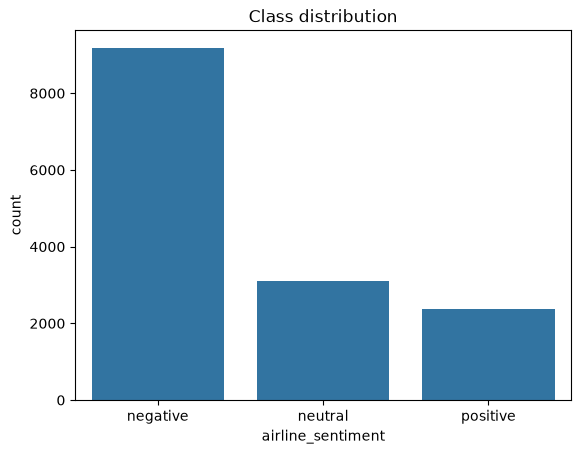

airline_sentiment
negative    0.627
neutral     0.212
positive    0.161
Name: proportion, dtype: float64


In [20]:
sns.countplot(data=df, x="airline_sentiment", order=["negative", "neutral", "positive"])
plt.title("Class distribution")
plt.show()

print(df["airline_sentiment"].value_counts(normalize=True).round(3))

## 3. Text Preprocessing and Cleaning

In [21]:
df = df.drop_duplicates(subset="text").reset_index(drop=True)
df["clean_text"] = df["text"].apply(clean)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)

print(df.shape)
for _, r in df.sample(3, random_state=7).iterrows():
    print("RAW  :", r["text"])
    print("CLEAN:", r["clean_text"], "\n")

(14396, 5)
RAW  : @SouthwestAir boarding passes now compatible with #iPhone #Passbook 
http://t.co/1ESmMnIZEk
CLEAN: board pas compatible iphone passbook 

RAW  : @SouthwestAir no but seriously wtf? #nochill http://t.co/esd3XD5V1r
CLEAN: no seriously wtf nochill 

RAW  : @JetBlue's CEO battles to appease passengers and Wall Street - Waterbury Republican American http://t.co/Ur60Un86gy
CLEAN: ceo battle appease passenger wall street waterbury republican american 



## 4. Word Frequency Analysis

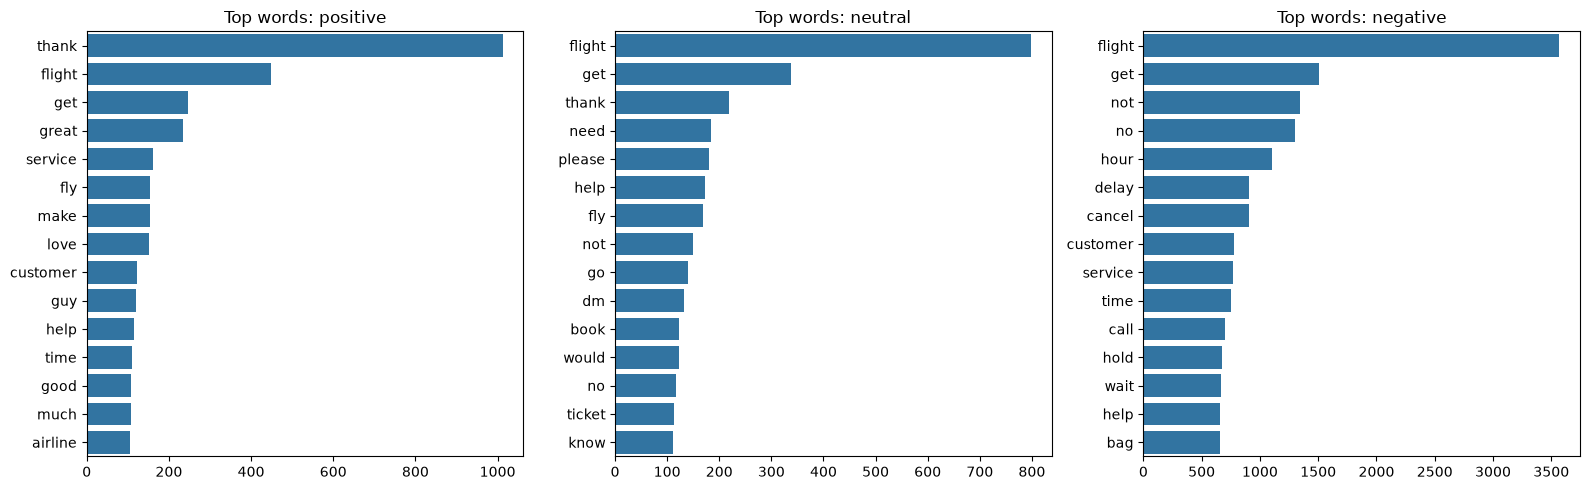

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, s in zip(axes, ["positive", "neutral", "negative"]):
    words = " ".join(df[df.airline_sentiment == s]["clean_text"]).split()
    top = Counter(words).most_common(15)
    sns.barplot(x=[c for _, c in top], y=[w for w, _ in top], ax=ax)
    ax.set_title(f"Top words: {s}")
plt.tight_layout()
plt.show()

## 5. Word Clouds: Positive vs Negative Tweets

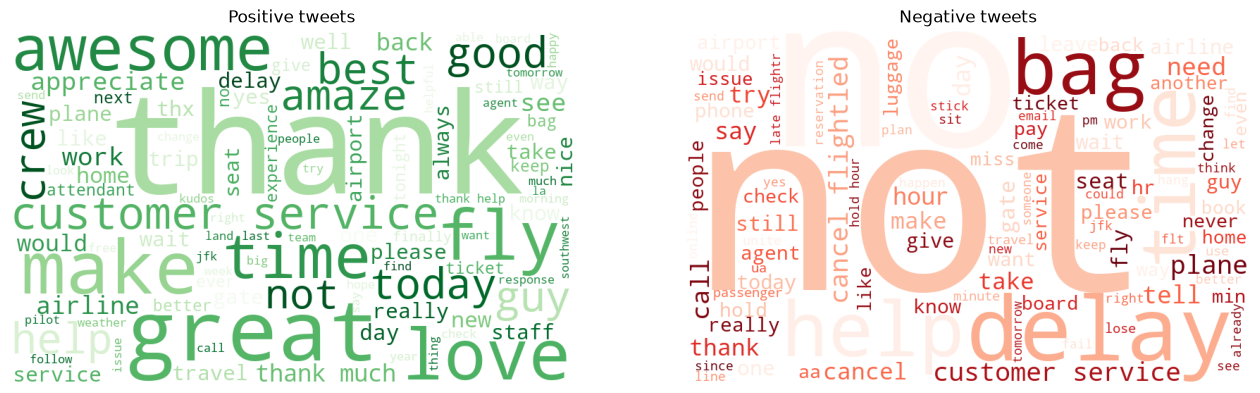

In [23]:
# Words common to ALL classes carry no sentiment, so hide them in the clouds only
noise = {"flight", "flights", "get", "go", "will", "us", "amp", "u", "im", "dont",
         "united", "usairways", "americanair", "southwestair", "jetblue", "virginamerica"}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, s, cmap in zip(axes, ["positive", "negative"], ["Greens", "Reds"]):
    text = " ".join(df[df.airline_sentiment == s]["clean_text"])
    wc = WordCloud(width=800, height=500, background_color="white",
                   colormap=cmap, max_words=100, stopwords=noise).generate(text)
    ax.imshow(wc)
    ax.axis("off")
    ax.set_title(f"{s.capitalize()} tweets")
plt.show()

## 6. Tweet Length Analysis

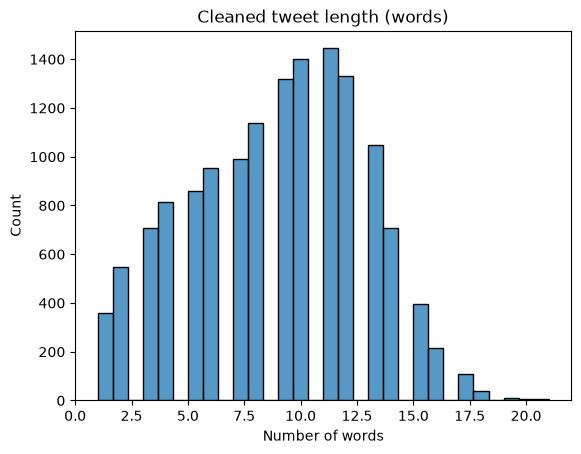

Average: 8.8
95th percentile: 15
Max: 21


In [24]:
df["word_count"] = df["clean_text"].str.split().str.len()

sns.histplot(df["word_count"], bins=30)
plt.title("Cleaned tweet length (words)")
plt.xlabel("Number of words")
plt.show()

print("Average:", round(df["word_count"].mean(), 1))
print("95th percentile:", int(df["word_count"].quantile(0.95)))
print("Max:", df["word_count"].max())

## 7. Saving the Cleaned Dataset

In [25]:
df.to_csv("clean_tweets.csv", index=False)
print("Saved:", df.shape)

Saved: (14396, 6)


## Observations:

- The dataset has 14,640 tweets, but the classes are not balanced. Around 63% are negative, 21% neutral and only 16% positive. So accuracy alone can fool me, and I will also look at F1-score.
- The raw tweets were very messy, with links, @mentions, hashtags and punctuation. After cleaning (lowercase, regex, lemmatization, stop words) they became short keyword lists, like "board pas compatible iphone passbook".
- I removed duplicate tweets, which left 14,396 tweets.
- I kept words like "not", "no" and "never" on purpose. If I removed them, "not good" would look the same as "good".
- In the word clouds, "thank" and "great" are the biggest words in positive tweets. In negative tweets I saw "not" and "no" a lot.
- "flight" and the airline names appear in every class, so they don't help the model decide sentiment. I hid them only in the word clouds.
- The average tweet has about 9 words, and 95% have 15 words or fewer. I will use 15 as the padding length for the LSTM.

## 8. Train-Test Split

In [26]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    df["clean_text"], df["airline_sentiment"],
    test_size=0.2, stratify=df["airline_sentiment"], random_state=42)

print("Train:", len(X_tr), " Test:", len(X_te))
print(y_tr.value_counts(normalize=True).round(3))

Train: 11516  Test: 2880
airline_sentiment
negative    0.630
neutral     0.211
positive    0.159
Name: proportion, dtype: float64


## 9. Feature Engineering: TF-IDF Vectorization

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
Xtr = tfidf.fit_transform(X_tr)   # learn vocabulary from TRAIN only
Xte = tfidf.transform(X_te)       # apply the same vocabulary to TEST

print("Train matrix:", Xtr.shape)
print("Test matrix:", Xte.shape)
print("Sample features:", tfidf.get_feature_names_out()[:10])

Train matrix: (11516, 10000)
Test matrix: (2880, 10000)
Sample features: ['aa' 'aa agent' 'aa amp' 'aa customer' 'aa delay' 'aa dfw' 'aa employee'
 'aa family' 'aa flight' 'aa gate']


## 10. Building the Models: Logistic Regression and Naive Bayes

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(Xtr, y_tr)

nb = MultinomialNB()
nb.fit(Xtr, y_tr)

print("Both models trained")

Both models trained


## 11. Model Evaluation: Accuracy, Precision, Recall and F1-Score

In [29]:
from sklearn.metrics import classification_report, accuracy_score

for name, model in [("Logistic Regression", lr), ("Naive Bayes", nb)]:
    pred = model.predict(Xte)
    print("=====", name, "=====")
    print("Accuracy:", round(accuracy_score(y_te, pred), 4))
    print(classification_report(y_te, pred))

===== Logistic Regression =====
Accuracy: 0.7705
              precision    recall  f1-score   support

    negative       0.89      0.82      0.85      1815
     neutral       0.56      0.65      0.60       608
    positive       0.67      0.74      0.70       457

    accuracy                           0.77      2880
   macro avg       0.71      0.74      0.72      2880
weighted avg       0.79      0.77      0.78      2880

===== Naive Bayes =====
Accuracy: 0.7156
              precision    recall  f1-score   support

    negative       0.70      0.99      0.82      1815
     neutral       0.74      0.19      0.31       608
    positive       0.90      0.33      0.48       457

    accuracy                           0.72      2880
   macro avg       0.78      0.50      0.54      2880
weighted avg       0.74      0.72      0.66      2880



## 12. Confusion Matrix

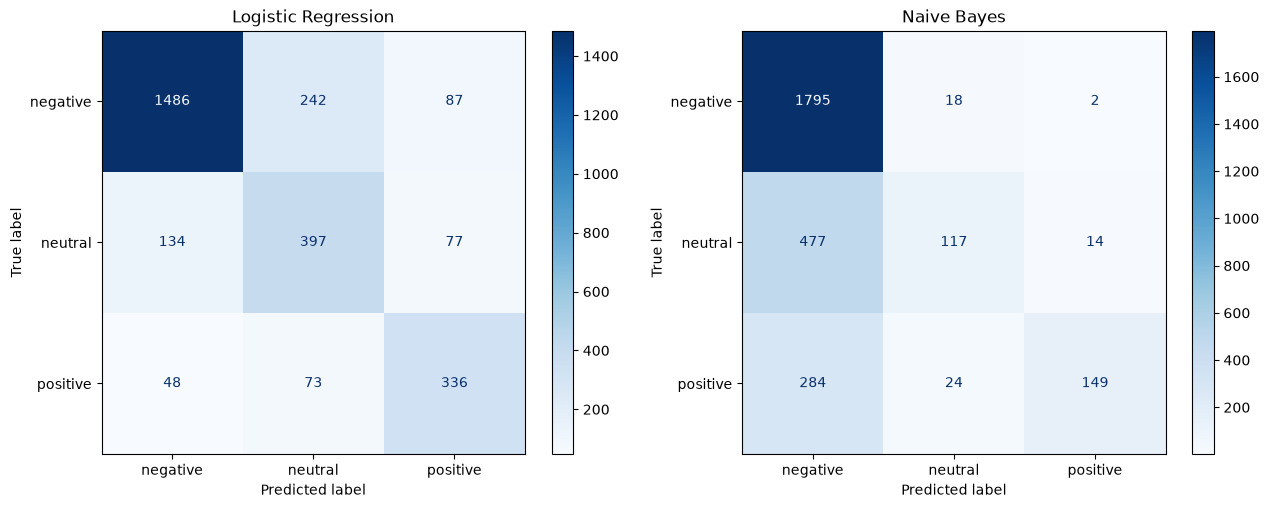

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, [("Logistic Regression", lr), ("Naive Bayes", nb)]):
    ConfusionMatrixDisplay.from_estimator(model, Xte, y_te, cmap="Blues", ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 13. Testing with Custom Inputs

In [31]:
tests = [
    "The service was amazing!",
    "I waited 4 hours just to get a cold burger.",
    "The flight was okay, nothing special.",
    "Great, another delayed flight. Just what I needed.",
    "Thank you for the quick help with my baggage!",
]

for t in tests:
    vec = tfidf.transform([clean(t)])
    print(f"{t}\n   LR: {lr.predict(vec)[0]:9} | NB: {nb.predict(vec)[0]}\n")

The service was amazing!
   LR: positive  | NB: positive

I waited 4 hours just to get a cold burger.
   LR: negative  | NB: negative

The flight was okay, nothing special.
   LR: neutral   | NB: negative

Great, another delayed flight. Just what I needed.
   LR: negative  | NB: negative

Thank you for the quick help with my baggage!
   LR: positive  | NB: positive



## 14. Saving the Models and Results

In [32]:
import joblib
from sklearn.metrics import precision_recall_fscore_support

joblib.dump(tfidf, "tfidf.pkl")
joblib.dump(lr, "lr_model.pkl")

rows = []
for name, model in [("TF-IDF + Logistic Regression", lr), ("TF-IDF + Naive Bayes", nb)]:
    pred = model.predict(Xte)
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, average="macro")
    rows.append({"Model": name, "Accuracy": round(accuracy_score(y_te, pred), 4),
                 "Precision": round(p, 4), "Recall": round(r, 4), "F1 (macro)": round(f, 4)})

results = pd.DataFrame(rows)
results.to_csv("classical_results.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1 (macro)
0,TF-IDF + Logistic Regression,0.7705,0.7068,0.7356,0.7190
1,TF-IDF + Naive Bayes,0.7156,0.7804,0.5025,0.5352


## Observations:

| Model | Accuracy | Precision | Recall | F1 (macro) |
|---|---|---|---|---|
| TF-IDF + Logistic Regression | 0.7705 | 0.7068 | 0.7356 | 0.7190 |
| TF-IDF + Naive Bayes | 0.7156 | 0.7804 | 0.5025 | 0.5352 |

- Logistic Regression did better overall. I used class_weight="balanced", and it gave decent results for all three classes.
- Naive Bayes looked okay on accuracy (0.72), but the F1 of 0.54 shows a problem. It found 99% of negative tweets but only 19% of neutral and 33% of positive ones. It just predicts "negative" most of the time because that class is the biggest.
- Logistic Regression's biggest mistake was predicting neutral for 242 tweets that are really negative. Mild complaints can sound neutral.
- Both models got the two examples from the brief right ("The service was amazing!" is positive, and the cold burger tweet is negative).
- Naive Bayes called "The flight was okay, nothing special" negative, which is wrong. Logistic Regression correctly said neutral.
- The sarcastic tweet "Great, another delayed flight" was predicted negative, but I think that is only because of the word "delayed". TF-IDF does not look at word order, so it cannot really understand sarcasm.